# Compare Read Sorting Performances

## 0. Imports and Path Assignments

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import ConfusionMatrixDisplay
import sys
import os
sys.path.append(os.path.abspath(os.path.join("..")))
from helper.visualization import *
from helper.metrics import * 

from warnings import simplefilter
simplefilter("ignore")

In [2]:
data_dir = Path.cwd()/ "results"
fig_dir = Path.cwd() / "figures" 
fig_dir.mkdir(exist_ok=True, parents=True)
fig_dir_comparison = fig_dir / "comparison"
fig_dir_comparison.mkdir(exist_ok=True)

## 1. Load performance metrics for every read-sorting method

In [3]:
methods = ["xengsort_newindex", "icrg", "bamcmp", "xenofilter"]
# "bamcmp","icrg", 
dfs = [pd.read_csv(data_dir / f"{method}.csv") for method in methods]
df = pd.concat(dfs)
df.to_csv(data_dir / "merged.csv", index=False)

In [4]:

df["Sample_Name"] = df["Sample_Prefix"].map(sample_map)
df["Sample_ID"] = df["Sample_Name"].str.split(" ").apply(lambda x: "Mix " + x[1])


## 2. Visualization

### Across Mixture Datasets

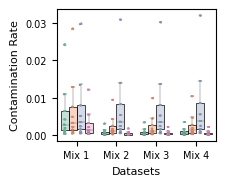

In [5]:
ax, pos = boxplot_tools(df, x="Sample_ID", y="Contamination_Rate", hue="Method", xlabel="Datasets", ylabel="Contamination Rate", figsize=mm_to_inches((60, 50)), legend=False, save=True, fig_dir=fig_dir_comparison, file_path="boxplot_contamination-rate_datasets.pdf")

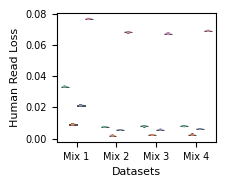

In [6]:
ax = boxplot_tools(df, x="Sample_ID", y="Human_Loss", hue="Method", xlabel="Datasets", ylabel="Human Read Loss", figsize=mm_to_inches((60, 50)), legend=False, save=True, fig_dir=fig_dir_comparison, file_path="boxplot_human-read-loss_datasets.pdf")

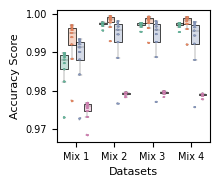

In [12]:
ax = boxplot_tools(df, x="Sample_ID", y="Score", hue="Method", xlabel="Datasets", ylabel="Accuracy Score", figsize=mm_to_inches((60, 50)), legend=False, save=True, fig_dir=fig_dir_comparison, file_path="boxplot_performance-score_datasets.pdf")

### Across Sequencing Depth

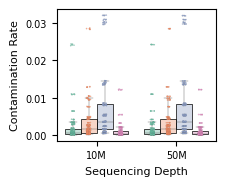

In [7]:
df["Sequencing Depth"] = (df["Total_Reads"] / 1_000_000 / 2).round().astype(int).astype(str) + "M"

ax = boxplot_tools(df, x="Sequencing Depth", y="Contamination_Rate", hue="Method", xlabel=None, ylabel="Contamination Rate", figsize=mm_to_inches((60, 50)), legend=False, save=True, fig_dir=fig_dir_comparison, file_path="boxplot_contamination-rate_sequencing-depths.pdf")


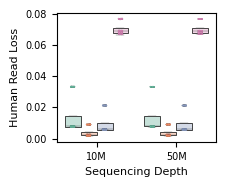

In [8]:

ax = boxplot_tools(df, x="Sequencing Depth", y="Human_Loss", hue="Method", xlabel=None, ylabel="Human Read Loss", figsize=mm_to_inches((60, 50)), legend=False, save=True, fig_dir=fig_dir_comparison, file_path="boxplot_human-read-loss_sequencing-depths.pdf")


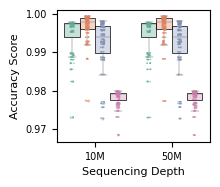

In [15]:

ax = boxplot_tools(df, x="Sequencing Depth", y="Score", hue="Method", xlabel=None, ylabel="Accuracy Score", figsize=mm_to_inches((60, 50)), legend=False, save=True, fig_dir=fig_dir_comparison, file_path="boxplot_performance-score_sequencing-depths.pdf")

### Across Human Content

<Axes: xlabel='Human Content [%]', ylabel='Human Read Loss'>

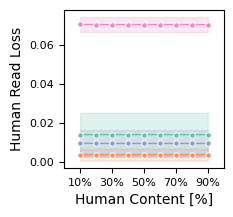

In [9]:


lineplot_tools(df, x = "Human_Ratio", y="Human_Loss", hue="Method", xlabel="Human Content [%]", ylabel="Human Read Loss",
    legend=False, percent=False, figsize=mm_to_inches((60, 60)), pos=pos,
    save=True, fig_dir=fig_dir_comparison, file_path="lineplot_human-read_loss_pct_human-ratio.svg")

<Axes: xlabel='Human Content [%]', ylabel='Contamination Rate'>

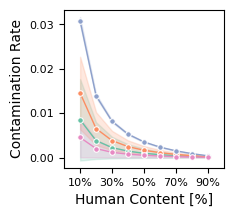

In [9]:
lineplot_tools(df, x="Human_Ratio", y="Contamination_Rate", hue="Method", xlabel = "Human Content [%]", ylabel="Contamination Rate", 
               legend=False, figsize=mm_to_inches((60, 60)), save=True, pos = pos,
               fig_dir = fig_dir_comparison, file_path="lineplot_contamination-rate_pct_human-ratio.svg")

<Axes: xlabel='Human Content [%]', ylabel='Accuracy Score'>

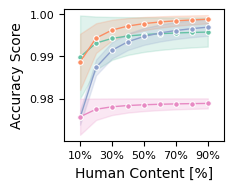

In [10]:
lineplot_tools(df, x="Human_Ratio", y="Score", hue="Method", ylabel="Accuracy Score", xlabel="Human Content [%]",
               legend=False, figsize=mm_to_inches((60, 50)), save=True, pos = pos, 
               fig_dir = fig_dir_comparison, file_path="lineplot_performance-score_human-ratio.pdf")
